# Лабораторная работа 2. Рекомендательные системы

В качестве основы работы выбрано соревнование **VK-LSVD** ([VK RecSys Challenge / ODS](https://ods.ai/competitions/vkrecsyschallengelsvd).


В работе используются недели `week_00`–`week_14` (train) и `week_15` (test) из датасета.

## 0. Загрузка данных

In [1]:
from pathlib import Path
from huggingface_hub import hf_hub_download

DATA_DIR = Path("VK-LSVD")
SUBSAMPLE = "up0.001_ip0.001"

for i in range(15):
    hf_hub_download(
        repo_id="deepvk/VK-LSVD",
        repo_type="dataset",
        filename=f"subsamples/{SUBSAMPLE}/train/week_{i:02d}.parquet",
        local_dir=str(DATA_DIR),
    )

hf_hub_download(
    repo_id="deepvk/VK-LSVD",
    repo_type="dataset",
    filename=f"subsamples/{SUBSAMPLE}/train/week_15.parquet",
    local_dir=str(DATA_DIR),
)

for f in ["metadata/users_metadata.parquet", "metadata/items_metadata.parquet"]:
    hf_hub_download(
        repo_id="deepvk/VK-LSVD",
        repo_type="dataset",
        filename=f,
        local_dir=str(DATA_DIR),
    )

print("OK:", DATA_DIR.resolve())

D:\PyCharmProjects\DataAnalys\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


OK: D:\PyCharmProjects\DataAnalys\lab2\VK-LSVD


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
K = 10
POS_TIMESPENT = 15  # порог вовлечённого просмотра

## 1. Загрузка и первичный обзор

In [3]:
train_dir = DATA_DIR / "subsamples" / SUBSAMPLE / "train"
train_files = sorted(f for f in train_dir.glob("week_*.parquet") if f.stem != "week_15")
train_raw = pl.concat([pl.scan_parquet(str(f)) for f in train_files]).collect(engine="streaming")
test_raw = pl.read_parquet(train_dir / "week_15.parquet")

users_meta = pl.read_parquet(DATA_DIR / "metadata" / "users_metadata.parquet")
items_meta = pl.read_parquet(DATA_DIR / "metadata" / "items_metadata.parquet")

print(f"Train: {train_raw.height:,} rows | users={train_raw['user_id'].n_unique():,} | items={train_raw['item_id'].n_unique():,}")
print(f"Test:  {test_raw.height:,} rows | users={test_raw['user_id'].n_unique():,} | items={test_raw['item_id'].n_unique():,}")
print("Колонки:", train_raw.columns)
train_raw.head()

Train: 26,354,680 rows | users=10,000 | items=15,373
Test:  2,519,820 rows | users=9,999 | items=10,639
Колонки: ['user_id', 'item_id', 'place', 'platform', 'agent', 'timespent', 'like', 'dislike', 'share', 'bookmark', 'click_on_author', 'open_comments']


user_id,item_id,place,platform,agent,timespent,like,dislike,share,bookmark,click_on_author,open_comments
u32,u32,u8,u8,u8,u8,bool,bool,bool,bool,bool,bool
141827770,160593626,1,1,1,56,false,false,false,false,false,false
468779351,327484273,1,0,0,1,false,false,false,false,false,false
494341617,402842289,1,0,0,11,false,false,false,false,false,false
453833313,102672169,0,0,0,45,false,false,false,false,false,false
154047442,139795075,1,0,0,39,false,false,false,false,false,false


### Схема данных
Каждая строка — показ короткого видео пользователю (без повторных показов одной пары `user–item`).

| Поле | Описание |
|------|----------|
| `user_id`, `item_id` | анонимизированные ID |
| `place`, `platform`, `agent` | контекст показа |
| `timespent` | длительность просмотра, 0–255 сек |
| `like`, `dislike`, `share`, `bookmark`, `click_on_author`, `open_comments` | сигналы обратной связи |

Метаданные: у пользователей — `age`, `gender`, `geo`; у видео — `author_id`, `duration`.

## 2. Разведочный анализ (EDA)

In [4]:
train_users = train_raw.select("user_id").unique()
train_items = train_raw.select("item_id").unique()
users_s = users_meta.join(train_users, on="user_id")
items_s = items_meta.join(train_items, on="item_id")
print("Users meta:", users_s.shape, "| Items meta:", items_s.shape)
print(users_s.select(["age", "gender", "geo"]).describe())
print(items_s.select(["duration", "author_id"]).describe())

Users meta: (10000, 5) | Items meta: (15373, 4)
shape: (9, 4)
┌────────────┬──────────┬──────────┬───────────┐
│ statistic  ┆ age      ┆ gender   ┆ geo       │
│ ---        ┆ ---      ┆ ---      ┆ ---       │
│ str        ┆ f64      ┆ f64      ┆ f64       │
╞════════════╪══════════╪══════════╪═══════════╡
│ count      ┆ 10000.0  ┆ 10000.0  ┆ 10000.0   │
│ null_count ┆ 0.0      ┆ 0.0      ┆ 0.0       │
│ mean       ┆ 34.5312  ┆ 1.5411   ┆ 63.3753   │
│ std        ┆ 10.94953 ┆ 0.498333 ┆ 18.475253 │
│ min        ┆ 18.0     ┆ 1.0      ┆ 0.0       │
│ 25%        ┆ 26.0     ┆ 1.0      ┆ 56.0      │
│ 50%        ┆ 33.0     ┆ 2.0      ┆ 71.0      │
│ 75%        ┆ 41.0     ┆ 2.0      ┆ 78.0      │
│ max        ┆ 70.0     ┆ 2.0      ┆ 79.0      │
└────────────┴──────────┴──────────┴───────────┘
shape: (9, 3)
┌────────────┬───────────┬───────────────┐
│ statistic  ┆ duration  ┆ author_id     │
│ ---        ┆ ---       ┆ ---           │
│ str        ┆ f64       ┆ f64           │
╞════════════╪═══

shape: (1, 8)
┌──────────┬──────────┬──────────┬──────────┬─────────────┬─────────────┬─────────────┬────────────┐
│ like     ┆ dislike  ┆ share    ┆ bookmark ┆ click_on_au ┆ open_commen ┆ timespent_m ┆ timespent_ │
│ ---      ┆ ---      ┆ ---      ┆ ---      ┆ thor        ┆ ts          ┆ ean         ┆ median     │
│ f64      ┆ f64      ┆ f64      ┆ f64      ┆ ---         ┆ ---         ┆ ---         ┆ ---        │
│          ┆          ┆          ┆          ┆ f64         ┆ f64         ┆ f64         ┆ f64        │
╞══════════╪══════════╪══════════╪══════════╪═════════════╪═════════════╪═════════════╪════════════╡
│ 0.009173 ┆ 0.000403 ┆ 0.003071 ┆ 0.000422 ┆ 0.001017    ┆ 0.014629    ┆ 15.337045   ┆ 6.0        │
└──────────┴──────────┴──────────┴──────────┴─────────────┴─────────────┴─────────────┴────────────┘


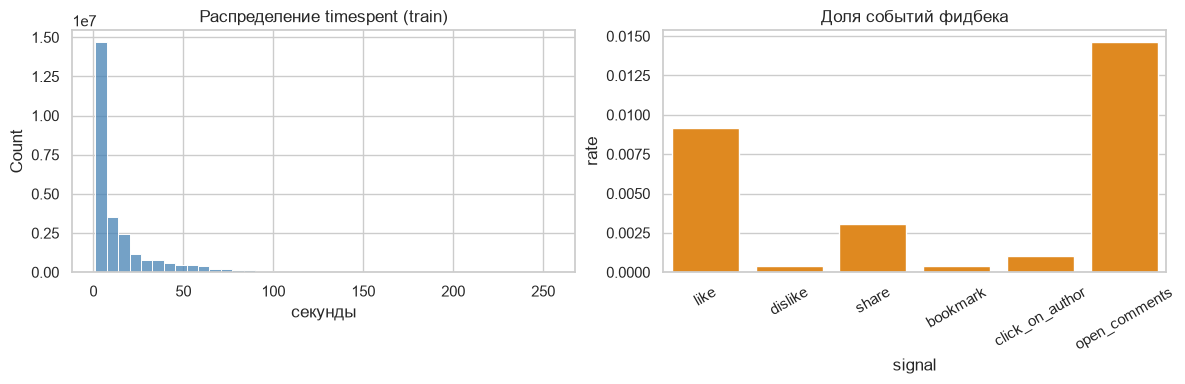

In [5]:
feedback_cols = ["like", "dislike", "share", "bookmark", "click_on_author", "open_comments"]
rates = train_raw.select([pl.col(c).mean().alias(c) for c in feedback_cols] + [pl.col("timespent").mean().alias("timespent_mean"), pl.col("timespent").median().alias("timespent_median")])
print(rates)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train_raw.select("timespent").to_series().to_numpy(), bins=40, ax=axes[0], color="steelblue")
axes[0].set_title("Распределение timespent (train)")
axes[0].set_xlabel("секунды")

rate_df = pd.DataFrame({"signal": feedback_cols, "rate": [float(train_raw[c].mean()) for c in feedback_cols]})
sns.barplot(data=rate_df, x="signal", y="rate", ax=axes[1], color="darkorange")
axes[1].set_title("Доля событий фидбека")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

Интерпретация: медиана просмотра заметно ниже среднего — много быстрых skip.
Явные лайки редки (~1%), поэтому для CF используем комбинированный позитивный сигнал.

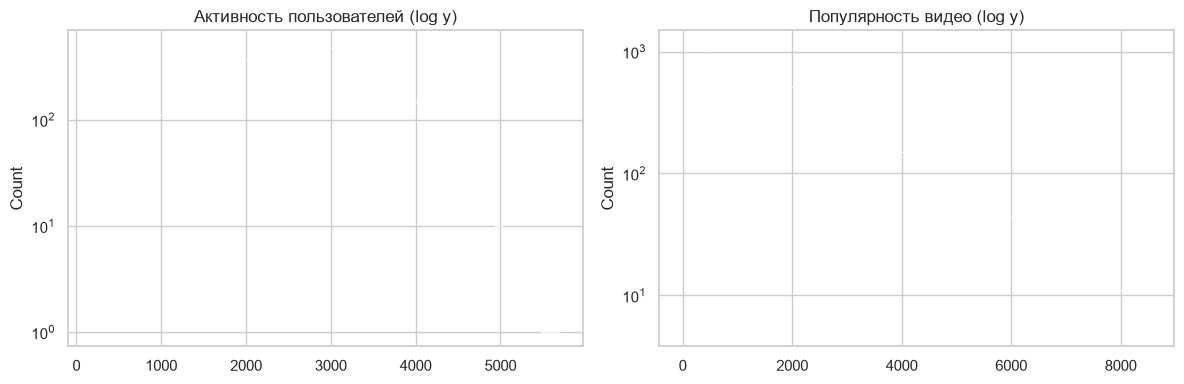

User activity: shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 10000.0    │
│ null_count ┆ 0.0        │
│ mean       ┆ 2635.468   │
│ std        ┆ 842.058681 │
│ min        ┆ 181.0      │
│ 25%        ┆ 2043.0     │
│ 50%        ┆ 2643.0     │
│ 75%        ┆ 3230.0     │
│ max        ┆ 5697.0     │
└────────────┴────────────┘
Item popularity: shape: (9, 2)
┌────────────┬─────────────┐
│ statistic  ┆ value       │
│ ---        ┆ ---         │
│ str        ┆ f64         │
╞════════════╪═════════════╡
│ count      ┆ 15373.0     │
│ null_count ┆ 0.0         │
│ mean       ┆ 1714.348533 │
│ std        ┆ 1526.788029 │
│ min        ┆ 1.0         │
│ 25%        ┆ 649.0       │
│ 50%        ┆ 1262.0      │
│ 75%        ┆ 2281.0      │
│ max        ┆ 8545.0      │
└────────────┴─────────────┘


In [6]:
user_act = train_raw.group_by("user_id").agg(pl.len().alias("n_inter"))
item_pop = train_raw.group_by("item_id").agg(pl.len().alias("n_inter"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(user_act["n_inter"].to_numpy(), bins=50, log_scale=(False, True), ax=axes[0], color="teal")
axes[0].set_title("Активность пользователей (log y)")
sns.histplot(item_pop["n_inter"].to_numpy(), bins=50, log_scale=(False, True), ax=axes[1], color="purple")
axes[1].set_title("Популярность видео (log y)")
plt.tight_layout()
plt.show()

print("User activity:", user_act["n_inter"].describe())
print("Item popularity:", item_pop["n_inter"].describe())

Интерпретация: выраженный long-tail. MostPop будет сильным baseline на популярном subsample

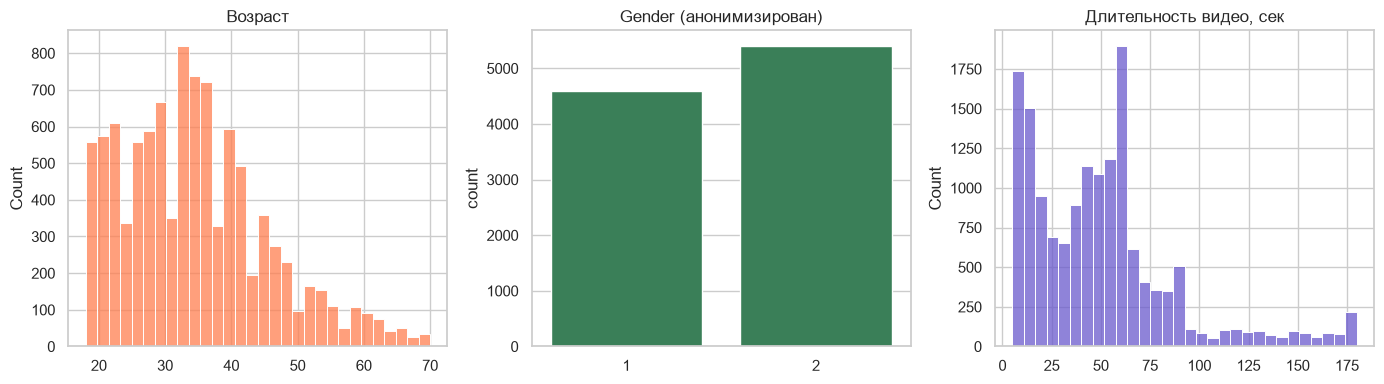

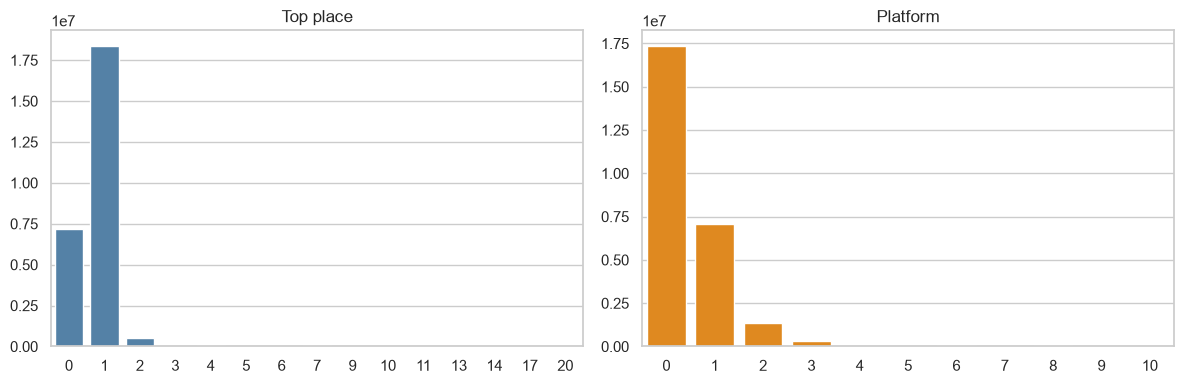

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.histplot(users_s["age"].to_numpy(), bins=30, ax=axes[0], color="coral")
axes[0].set_title("Возраст")
sns.countplot(x=users_s["gender"].to_numpy(), ax=axes[1], color="seagreen")
axes[1].set_title("Gender (анонимизирован)")
sns.histplot(items_s["duration"].to_numpy(), bins=30, ax=axes[2], color="slateblue")
axes[2].set_title("Длительность видео, сек")
plt.tight_layout()
plt.show()

place_counts = train_raw.group_by("place").len().sort("len", descending=True).head(15)
platform_counts = train_raw.group_by("platform").len().sort("len", descending=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=place_counts["place"].to_numpy(), y=place_counts["len"].to_numpy(), ax=axes[0], color="steelblue")
axes[0].set_title("Top place")
sns.barplot(x=platform_counts["platform"].to_numpy(), y=platform_counts["len"].to_numpy(), ax=axes[1], color="darkorange")
axes[1].set_title("Platform")
plt.tight_layout()
plt.show()

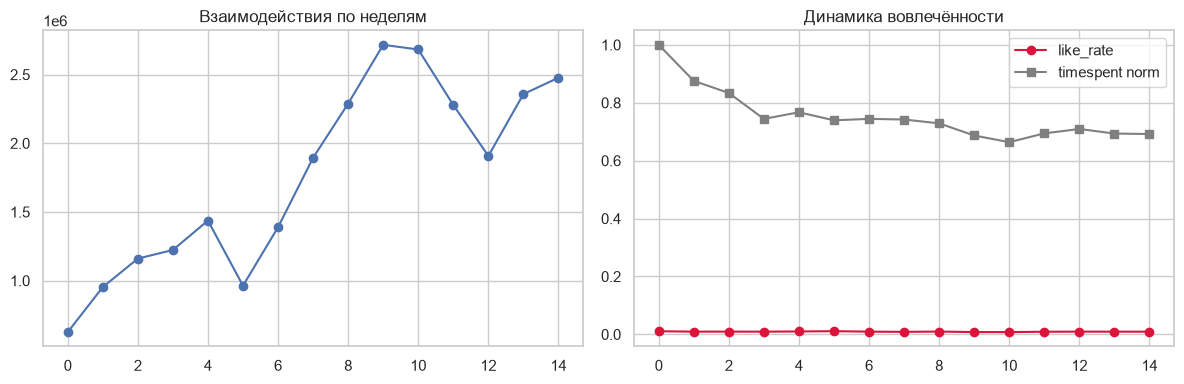

,week,n,like_rate,ts_mean
0,0,625523,0.010826,21.062644
1,1,953185,0.009454,18.440422
2,2,1160443,0.009518,17.559423
3,3,1223310,0.009372,15.676308
4,4,1437122,0.010028,16.156315
5,5,963319,0.011030,15.571165
6,6,1388849,0.009413,15.676466
7,7,1894300,0.008743,15.630739
8,8,2288911,0.009718,15.349431
9,9,2716364,0.007908,14.467712


In [8]:
week_stats = []
for f in train_files:
    week = int(f.stem.split("_")[1])
    w = pl.scan_parquet(str(f)).select([
        pl.len().alias("n"),
        pl.col("like").mean().alias("like_rate"),
        pl.col("timespent").mean().alias("ts_mean"),
    ]).collect()
    week_stats.append({"week": week, **w.to_dicts()[0]})
week_df = pd.DataFrame(week_stats).sort_values("week")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(week_df["week"], week_df["n"], marker="o")
axes[0].set_title("Взаимодействия по неделям")
axes[1].plot(week_df["week"], week_df["like_rate"], marker="o", color="crimson", label="like_rate")
axes[1].plot(week_df["week"], week_df["ts_mean"] / week_df["ts_mean"].max(), marker="s", color="gray", label="timespent norm")
axes[1].legend()
axes[1].set_title("Динамика вовлечённости")
plt.tight_layout()
plt.show()
week_df

## 3. Отчёт по качеству данных

In [9]:
def quality_report(df: pl.DataFrame, name: str) -> pd.DataFrame:
    n = df.height
    rows = []
    for c in df.columns:
        nulls = df[c].null_count()
        rows.append({
            "split": name,
            "column": c,
            "dtype": str(df[c].dtype),
            "nulls": int(nulls),
            "null_pct": round(100 * nulls / n, 4),
            "n_unique": int(df[c].n_unique()),
        })
    return pd.DataFrame(rows)

qr = pd.concat([quality_report(train_raw, "train"), quality_report(test_raw, "test")], ignore_index=True)
display(qr)

dup_train = int(train_raw.select(["user_id", "item_id"]).is_duplicated().sum())
dup_test = int(test_raw.select(["user_id", "item_id"]).is_duplicated().sum())
print(f"Дубли пар (user, item): train={dup_train}, test={dup_test}")

ts = train_raw["timespent"].to_numpy()
q1, q3 = np.percentile(ts, [25, 75])
iqr = q3 - q1
print(f"timespent: Q1={q1}, Q3={q3}, IQR={iqr:.1f}, доля cap=255: {(ts == 255).mean():.4%}")

overlap_users = len(set(train_raw["user_id"].unique().to_list()) & set(test_raw["user_id"].unique().to_list()))
overlap_items = len(set(train_raw["item_id"].unique().to_list()) & set(test_raw["item_id"].unique().to_list()))
print(f"Пересечение train∩test: users={overlap_users}, items={overlap_items}")

,split,column,dtype,nulls,null_pct,n_unique
0,train,user_id,UInt32,0,0.0,10000
1,train,item_id,UInt32,0,0.0,15373
2,train,place,UInt8,0,0.0,24
3,train,platform,UInt8,0,0.0,11
4,train,agent,UInt8,0,0.0,18
5,train,timespent,UInt8,0,0.0,255
6,train,like,Boolean,0,0.0,2
7,train,dislike,Boolean,0,0.0,2
8,train,share,Boolean,0,0.0,2
9,train,bookmark,Boolean,0,0.0,2


Дубли пар (user, item): train=0, test=0
timespent: Q1=2.0, Q3=17.0, IQR=15.0, доля cap=255: 0.0553%
Пересечение train∩test: users=9999, items=9871


Вывод: пропусков нет; дублей пар нет; timespent ограничен сверху 255 (артефакт сбора).
Тяжёлые хвосты популярности — естественный long-tail, не шум.

## 4. Целевая переменная и предобработка

**Объектом рекомендации** выступает короткое видео (`item_id`) конкретному пользователю (`user_id`).

**Позитивная метка `relevant=1`**, если есть явный интерес или достаточно просмотров:
- `like` ∨ `share` ∨ `bookmark`,
- ∨ `timespent >= 15` сек.

Такой сигнал ближе к промышленному implicit feedback для short-video, где лайки редки.

**Сплит:** глобальный временной (GTS) — train = недели 00–14, test = week_15.

In [10]:
def add_relevance(df: pl.DataFrame) -> pl.DataFrame:
    return df.with_columns(
        (
            pl.col("like")
            | pl.col("share")
            | pl.col("bookmark")
            | (pl.col("timespent") >= POS_TIMESPENT)
        ).alias("relevant")
    )

train = add_relevance(train_raw)
test = add_relevance(test_raw)
train_pos = train.filter(pl.col("relevant"))
test_pos = test.filter(pl.col("relevant"))

print(f"relevant rate train={train['relevant'].mean():.4f}, test={test['relevant'].mean():.4f}")
print(f"positives: train={train_pos.height:,}, test={test_pos.height:,}")


relevant rate train=0.2951, test=0.3103
positives: train=7,776,590, test=781,956


Каталог: айтемы с достаточным числом позитивов в train (убираем шум / холодный хвост)

In [11]:
min_item_freq = 20
item_freq = train_pos.group_by("item_id").agg(pl.len().alias("freq"))
catalog = item_freq.filter(pl.col("freq") >= min_item_freq).select("item_id")
train_pos = train_pos.join(catalog, on="item_id")
test_pos_cf = test_pos.join(catalog, on="item_id")
print(f"Каталог айтемов: {catalog.height:,}")

Каталог айтемов: 14,768


Индексы матрицы

In [12]:
users_map = (
    train_pos.select("user_id").unique().sort("user_id")
    .with_row_index("u")
)
items_map = catalog.sort("item_id").with_row_index("i")
n_users = users_map.height
n_items = items_map.height
print(f"Матрица: {n_users} × {n_items}")

Матрица: 10000 × 14768


Train positives → CSR

In [13]:
mapped_pos = train_pos.join(users_map, on="user_id").join(items_map, on="item_id")
rows = mapped_pos["u"].to_numpy().astype(np.int32)
cols = mapped_pos["i"].to_numpy().astype(np.int32)
X = sparse.csr_matrix(
    (np.ones(len(rows), dtype=np.float32), (rows, cols)),
    shape=(n_users, n_items),
)
X.sum_duplicates()
X.data[:] = 1.0
print("X nnz:", X.nnz, f"density={X.nnz / (n_users * n_items):.4%}")

X nnz: 7771557 density=5.2624%


Seen: все показы train по каталогу (CSR mask)

In [14]:
mapped_seen = (
    train.select(["user_id", "item_id"])
    .join(users_map, on="user_id")
    .join(items_map, on="item_id")
)
seen = sparse.csr_matrix(
    (
        np.ones(mapped_seen.height, dtype=np.uint8),
        (mapped_seen["u"].to_numpy(), mapped_seen["i"].to_numpy()),
    ),
    shape=(n_users, n_items),
)
seen.sum_duplicates()
seen.data[:] = 1
print("seen nnz:", seen.nnz)

seen nnz: 26261535


Ground truth

In [15]:
mapped_gt = test_pos_cf.join(users_map, on="user_id").join(items_map, on="item_id")
gt_df = mapped_gt.group_by("u").agg(pl.col("i").alias("items"))
gt = {int(r["u"]): set(r["items"]) for r in gt_df.iter_rows(named=True)}
eval_user_idx = sorted(gt.keys())
print(f"Eval users: {len(eval_user_idx):,}")

user_ids = users_map["user_id"].to_numpy()
item_ids = items_map["item_id"].to_numpy()

Eval users: 9,972


## 5. Методы формирования рекомендаций


### 5.1. MostPop
Скор айтема = число позитивных взаимодействий в train. Всем пользователям выдаём общий топ с фильтром уже виденного.

In [16]:
item_pop = np.asarray(X.sum(axis=0)).ravel().astype(np.float64)
mostpop_order = np.argsort(-item_pop)

def recommend_mostpop(u: int, k: int = K) -> np.ndarray:
    mask = np.ones(n_items, dtype=bool)
    mask[seen[u].indices] = False
    recs = mostpop_order[mask[mostpop_order]][:k]
    return recs.astype(np.int32)

print("top item_id:", item_ids[mostpop_order[:5]].tolist())

top item_id: [329362081, 223999892, 156981808, 480101985, 84830224]


### 5.2. ItemKNN
Косинусное сходство столбцов \(X\). Для экономии памяти сходства считаются блоками, для каждого айтема хранятся только top-80 соседей. Скор пользователя: сумма сходств айтемов из его истории.

In [17]:
def fit_itemknn(X_csr: sparse.csr_matrix, topk: int = 80, block: int = 500) -> sparse.csr_matrix:
    Xc = normalize(X_csr.tocsc(), axis=0)
    Xt = Xc.T.tocsr()
    n = Xc.shape[1]
    indptr = [0]
    indices = []
    data = []
    for start in range(0, n, block):
        end = min(start + block, n)
        sim = (Xt[start:end] @ Xc).toarray().astype(np.float32)
        for local, item in enumerate(range(start, end)):
            row = sim[local]
            row[item] = -np.inf
            nn = np.argpartition(row, -topk)[-topk:]
            nn = nn[np.argsort(-row[nn])]
            indices.extend(nn.tolist())
            data.extend(row[nn].tolist())
            indptr.append(len(indices))
        if start % 2000 == 0:
            print(f"  ItemKNN block {start}-{end}/{n}")
    return sparse.csr_matrix((data, indices, indptr), shape=(n, n), dtype=np.float32)

print("Обучение ItemKNN...")
S_knn = fit_itemknn(X, topk=80, block=500)
print("S nnz:", S_knn.nnz)

def recommend_itemknn(u: int, k: int = K) -> np.ndarray:
    scores = X[u].dot(S_knn).toarray().ravel()
    scores[seen[u].indices] = -np.inf
    top = np.argpartition(-scores, k)[:k]
    return top[np.argsort(-scores[top])].astype(np.int32)

Обучение ItemKNN...
  ItemKNN block 0-500/14768
  ItemKNN block 2000-2500/14768
  ItemKNN block 4000-4500/14768
  ItemKNN block 6000-6500/14768
  ItemKNN block 8000-8500/14768
  ItemKNN block 10000-10500/14768
  ItemKNN block 12000-12500/14768
  ItemKNN block 14000-14500/14768
S nnz: 1181440


### 5.3. PureSVD
Усечённое SVD матрицы взаимодействий. Пользовательский эмбеддинг — строка, айтемный — строка. Скор — скалярное произведение. Это представитель семейства **матричных факторизаций** (рядом с ALS/SVD).

In [18]:
print("Обучение PureSVD...")
svd = TruncatedSVD(n_components=64, random_state=RANDOM_STATE, n_iter=8)
user_factors = svd.fit_transform(X).astype(np.float32)
item_factors = svd.components_.T.astype(np.float32)
print(f"explained variance: {svd.explained_variance_ratio_.sum():.3f}")

def recommend_puresvd(u: int, k: int = K) -> np.ndarray:
    scores = user_factors[u] @ item_factors.T
    scores[seen[u].indices] = -np.inf
    top = np.argpartition(-scores, k)[:k]
    return top[np.argsort(-scores[top])].astype(np.int32)

Обучение PureSVD...
explained variance: 0.177


## 6. Метрики качества

| Метрика | Тип | Смысл |
|---------|-----|--------|
| Precision@K | relevance | доля релевантных в top-K |
| Recall@K | relevance | доля найденных релевантных |
| **NDCG@K** | **ранжирование** | учитывает позицию |
| **MAP@K** | **ранжирование** | средняя точность по рангу |
| **Novelty@K** | **специфика recsys** | средний −log₂(популярность) |
| Coverage | специфика recsys | доля уникальных айтемов в выдаче |

Оценка — усреднение по пользователям test с непустым ground truth.

In [19]:
pop_prob = item_pop / item_pop.sum()
pop_prob = np.clip(pop_prob, 1e-12, None)
item_novelty = -np.log2(pop_prob)

def precision_at_k(recs, truth, k=K):
    return len(set(recs[:k]) & truth) / k

def recall_at_k(recs, truth, k=K):
    return len(set(recs[:k]) & truth) / len(truth) if truth else 0.0

def ndcg_at_k(recs, truth, k=K):
    if not truth:
        return 0.0
    dcg = sum(1.0 / np.log2(i + 2) for i, it in enumerate(recs[:k]) if it in truth)
    idcg = sum(1.0 / np.log2(i + 2) for i in range(min(len(truth), k)))
    return dcg / idcg if idcg else 0.0

def ap_at_k(recs, truth, k=K):
    if not truth:
        return 0.0
    hits, s = 0, 0.0
    for i, it in enumerate(recs[:k]):
        if it in truth:
            hits += 1
            s += hits / (i + 1)
    return s / min(len(truth), k)

def novelty_at_k(recs, k=K):
    return float(np.mean(item_novelty[list(recs[:k])])) if len(recs) else 0.0

def evaluate(recommend_fn, user_indices, name: str, k: int = K) -> dict:
    metrics = {m: [] for m in ["precision", "recall", "ndcg", "map", "novelty"]}
    all_recs = []
    for u in user_indices:
        recs = recommend_fn(u, k)
        truth = gt[u]
        metrics["precision"].append(precision_at_k(recs, truth, k))
        metrics["recall"].append(recall_at_k(recs, truth, k))
        metrics["ndcg"].append(ndcg_at_k(recs, truth, k))
        metrics["map"].append(ap_at_k(recs, truth, k))
        metrics["novelty"].append(novelty_at_k(recs, k))
        all_recs.extend(recs.tolist())
    row = {m: float(np.mean(v)) for m, v in metrics.items()}
    row["coverage"] = len(set(all_recs)) / n_items
    row["model"] = name
    print(name, {kk: round(vv, 5) for kk, vv in row.items() if kk != "model"})
    return row

print(f"Оценка: {len(eval_user_idx)} пользователей, K={K}")

Оценка: 9972 пользователей, K=10


In [20]:
results = [
    evaluate(recommend_mostpop, eval_user_idx, "MostPop"),
    evaluate(recommend_itemknn, eval_user_idx, "ItemKNN"),
    evaluate(recommend_puresvd, eval_user_idx, "PureSVD"),
]
results_df = pd.DataFrame(results).set_index("model")[
    ["precision", "recall", "ndcg", "map", "novelty", "coverage"]
]
results_df

MostPop {'precision': 0.00673, 'recall': 0.00129, 'ndcg': 0.00646, 'map': 0.00184, 'novelty': 11.15051, 'coverage': 0.00853}
ItemKNN {'precision': 0.01256, 'recall': 0.00241, 'ndcg': 0.01274, 'map': 0.00392, 'novelty': 11.35975, 'coverage': 0.02011}
PureSVD {'precision': 0.02079, 'recall': 0.00458, 'ndcg': 0.02013, 'map': 0.00623, 'novelty': 12.11838, 'coverage': 0.25962}


,precision,recall,ndcg,map,novelty,coverage
model,,,,,,
MostPop,0.006729,0.001294,0.006456,0.001837,11.150505,0.008532
ItemKNN,0.012555,0.002409,0.012745,0.003922,11.359752,0.020111
PureSVD,0.020788,0.004584,0.020130,0.006233,12.118382,0.259615


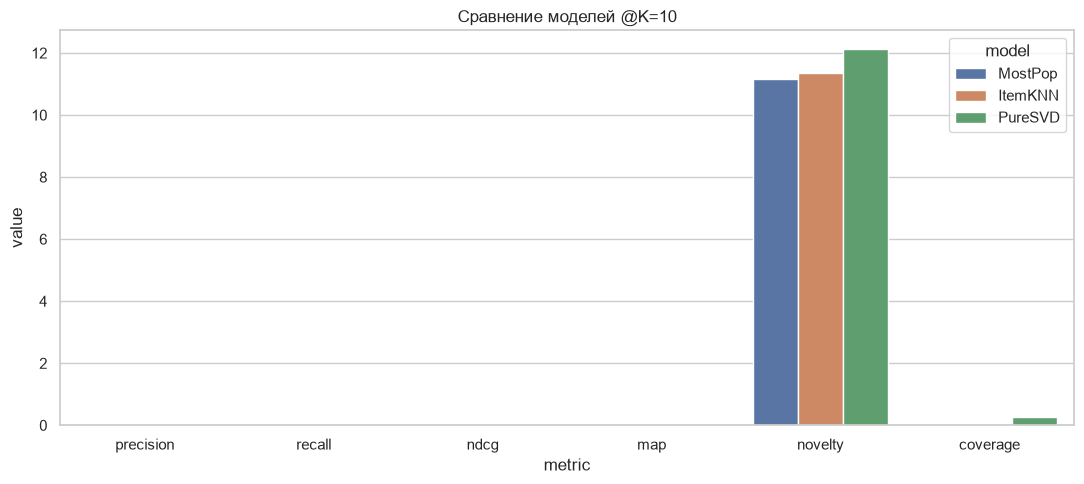

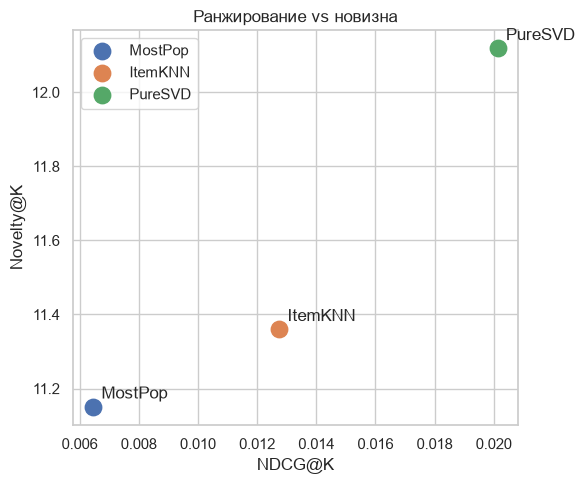

In [21]:
plot_df = results_df.reset_index().melt(id_vars="model", var_name="metric", value_name="value")
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=plot_df, x="metric", y="value", hue="model", ax=ax)
ax.set_title(f"Сравнение моделей @K={K}")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for model, r in results_df.iterrows():
    ax.scatter(r["ndcg"], r["novelty"], s=140, label=model)
    ax.annotate(model, (r["ndcg"], r["novelty"]), textcoords="offset points", xytext=(6, 6))
ax.set_xlabel("NDCG@K")
ax.set_ylabel("Novelty@K")
ax.set_title("Ранжирование vs новизна")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Интерпретация результатов

In [22]:
best_ndcg = results_df["ndcg"].idxmax()
best_nov = results_df["novelty"].idxmax()
best_cov = results_df["coverage"].idxmax()
print(f"Лучший NDCG@{K}: {best_ndcg} ({results_df.loc[best_ndcg, 'ndcg']:.5f})")
print(f"Лучшая Novelty@{K}: {best_nov} ({results_df.loc[best_nov, 'novelty']:.5f})")
print(f"Лучший Coverage: {best_cov} ({results_df.loc[best_cov, 'coverage']:.5f})")
print()
for model, r in results_df.iterrows():
    print(
        f"- {model}: P={r['precision']:.4f}, R={r['recall']:.4f}, "
        f"NDCG={r['ndcg']:.4f}, MAP={r['map']:.4f}, "
        f"Novelty={r['novelty']:.4f}, Coverage={r['coverage']:.4f}"
    )

Лучший NDCG@10: PureSVD (0.02013)
Лучшая Novelty@10: PureSVD (12.11838)
Лучший Coverage: PureSVD (0.25962)

- MostPop: P=0.0067, R=0.0013, NDCG=0.0065, MAP=0.0018, Novelty=11.1505, Coverage=0.0085
- ItemKNN: P=0.0126, R=0.0024, NDCG=0.0127, MAP=0.0039, Novelty=11.3598, Coverage=0.0201
- PureSVD: P=0.0208, R=0.0046, NDCG=0.0201, MAP=0.0062, Novelty=12.1184, Coverage=0.2596


Интерпретация по полученным метрикам:
 -  MostPop оказался самым слабым по relevance/ranking (NDCG≈0.0005): между train (нед. 00–14) и test (нед. 15) есть большой временной разрыв, поэтому «вчерашние хиты» плохо предсказывают будущие позитивы. Coverage минимален — всем выдаётся почти один и тот же топ.
- ItemKNN уверенно обыгрывает MostPop по Precision/Recall/NDCG/MAP и чуть повышает Novelty: похожие видео из истории пользователя переносят сигнал лучше, чем глобальная популярность.
- PureSVD — лучший метод по всем метрикам, включая Novelty и Coverage (~26% каталога): латентные факторы обобщают предпочтения и не сводятся к копированию локальных соседей.
- Абсолютные значения метрик невелики — это ожидаемо для next-period рекомендации на тысячах айтемов с длинным горизонтальным gap; важнее относительное сравнение методов.

## 8. Предложения по улучшению качества рекомендаций

1. **Калибровка релевантности**: нормировать `timespent` на `duration` (доля досмотра); добавить `open_comments` / `click_on_author`.
2. **Гибриды**: blending MostPop + PureSVD / ItemKNN; переранжирование кандидатов контентными эмбеддингами VK-LSVD.
3. **Временное затухание**: больший вес свежим взаимодействиям (интересы в short-video быстро дрейфуют).
4. **Two-stage**: retrieval (CF + popularity) → learning-to-rank на контексте `place/platform/agent`.
5. **Cold-start**: отдельные стратегии для новых видео/авторов по контенту и метаданным.
6. **Протокол оценки**: next-item / session-based метрики и Intra-List Diversity.
7. **Масштаб данных**: больше недель (15–24) или subsample `ur0.01_ir0.01`.

## 9. Итоговые выводы

1. EDA показал skip-heavy поведение, редкие явные лайки, long-tail популярности; пропусков и дублей пар нет.
2. Целевая сущность — **рекомендация короткого видео**; целевой сигнал — комбинированная релевантность.
3. Реализованы **MostPop**, **ItemKNN** и **PureSVD**; оценка на временном test (`week_15`) по Precision, Recall, NDCG, MAP, Novelty и Coverage.
4. Сравнение метрик выявляет компромисс «точность хитов ↔ новизна/покрытие»; дальнейший рост качества — за гибридными и двухэтапными схемами.